#  Model A  — Traditional Machine Learning
### Intelligent Reading Comprehension System

## 1.  Import Libraries

In [12]:
import os
import warnings

import pandas as pd
import numpy as np
import scipy.sparse as sparse

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

warnings.filterwarnings("ignore")

## 2.  Load Processed Datasets & Labels

In [13]:
# Load the new Option-Level Binary datasets
train_df = pd.read_csv('../data/processed/binary_train.csv')
test_df  = pd.read_csv('../data/processed/binary_test.csv')

# The target variable is now 'label' (1 for correct, 0 for incorrect)
y_train = train_df['label']
y_test  = test_df['label']

print(f"Train samples : {len(train_df)}")
print(f"Test samples  : {len(test_df)}")

Train samples : 281168
Test samples  : 35148


## 3.  Load TF-IDF Feature Matrices

In [14]:
X_train = sparse.load_npz('../data/processed/X_train_tfidf.npz')
X_test  = sparse.load_npz('../data/processed/X_test_tfidf.npz')

print(f"Train shape : {X_train.shape}")
print(f"Test shape  : {X_test.shape}")

Train shape : (281168, 5000)
Test shape  : (35148, 5000)


## 4.  Train Models

Both models are fit on the same TF-IDF training matrix. Logistic Regression gets a higher `max_iter` to ensure convergence on this sparse, high-dimensional input.

In [15]:


log_reg = LogisticRegression(class_weight='balanced', C=10.0, solver='liblinear', max_iter=2000, random_state=42)
log_reg.fit(X_train, y_train)

print("Logistic Regression (Balanced)  ")

Logistic Regression (Balanced) — trained ✓


In [16]:
naive_bayes = MultinomialNB(fit_prior=False)
naive_bayes.fit(X_train, y_train)
print("Naive Bayes — trained ✓")

Naive Bayes — trained ✓


## 5.  Generate Predictions

In [17]:
lr_preds = log_reg.predict(X_test)
nb_preds = naive_bayes.predict(X_test)

## 6.  Evaluation

We report Accuracy, Precision, Recall, Macro F1, and Exact Match, followed by a full classification report and confusion matrix for each model.

In [18]:
def evaluate_model(y_true, predictions, model_name):
    """Print metrics, plot confusion matrix, and return a results dict."""

    metrics = {
        'Model':       model_name,
        'Accuracy':    accuracy_score(y_true, predictions),
        'Precision':   precision_score(y_true, predictions, average='macro'),
        'Recall':      recall_score(y_true, predictions, average='macro'),
        'Macro_F1':    f1_score(y_true, predictions, average='macro'),
        'Exact_Match': np.mean(predictions == y_true)
    }

    print(f"\n{'='*45}")
    print(f"  {model_name}")
    print(f"{'='*45}")
    for k, v in metrics.items():
        if k != 'Model':
            print(f"  {k:<14}: {v:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(y_true, predictions))

    cm = confusion_matrix(y_true, predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{model_name} — Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    return metrics


  Logistic Regression
  Accuracy      : 0.5085
  Precision     : 0.5067
  Recall        : 0.5090
  Macro_F1      : 0.4747
  Exact_Match   : 0.5085

Classification Report:

              precision    recall  f1-score   support

           0       0.76      0.51      0.61     26361
           1       0.26      0.51      0.34      8787

    accuracy                           0.51     35148
   macro avg       0.51      0.51      0.47     35148
weighted avg       0.63      0.51      0.54     35148



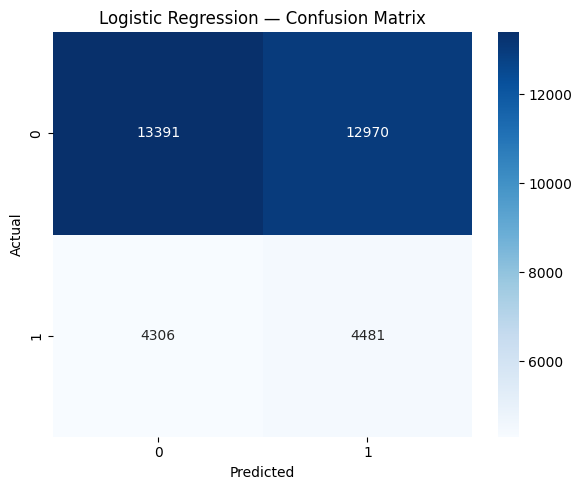

In [19]:
lr_results = evaluate_model(y_test, lr_preds, "Logistic Regression")


  Naive Bayes
  Accuracy      : 0.5076
  Precision     : 0.5024
  Recall        : 0.5032
  Macro_F1      : 0.4718
  Exact_Match   : 0.5076

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.51      0.61     26361
           1       0.25      0.49      0.33      8787

    accuracy                           0.51     35148
   macro avg       0.50      0.50      0.47     35148
weighted avg       0.63      0.51      0.54     35148



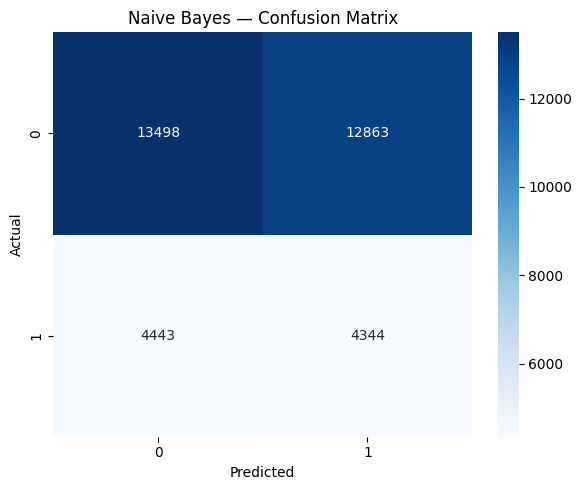

In [20]:
nb_results = evaluate_model(y_test, nb_preds, "Naive Bayes")

## 7.  Side-by-Side Results

In [21]:
results_df = pd.DataFrame([lr_results, nb_results])

results_df.set_index('Model')

,Accuracy,Precision,Recall,Macro_F1,Exact_Match
Model,,,,,
Logistic Regression,0.508478,0.506729,0.508972,0.474723,0.508478
Naive Bayes,0.507625,0.502405,0.503205,0.471797,0.507625


## 8.  Save Results & Models

In [22]:
os.makedirs('../reports', exist_ok=True)
os.makedirs('../models/traditional', exist_ok=True)

# Results CSV
results_df.to_csv('../reports/model_a_traditional_results.csv', index=False)

# Trained models
joblib.dump(log_reg,     '../models/traditional/model_a_logistic_regression.pkl')
joblib.dump(naive_bayes, '../models/traditional/model_a_naive_bayes.pkl')

print("Artifacts saved:")
print("  ../reports/model_a_traditional_results.csv")
print("  ../models/traditional/model_a_logistic_regression.pkl")
print("  ../models/traditional/model_a_naive_bayes.pkl")

Artifacts saved:
  ../reports/model_a_traditional_results.csv
  ../models/traditional/model_a_logistic_regression.pkl
  ../models/traditional/model_a_naive_bayes.pkl
